## 🏦 Business Problem Definition

This project aims to investigate credit card transactions using descriptive and inferential statistical techniques. The analysis focuses on understanding transaction characteristics, identifying patterns associated with fraudulent activities, and applying probability distributions to real-world financial data.

The statistical analysis will be conducted using Python, with particular attention to the Binomial, Poisson, and Normal distributions. The findings will be interpreted to evaluate the suitability of each statistical distribution for describing the selected dataset.

**🎯 Objectives:**

- Explore and understand the structure of the dataset.
- Perform descriptive statistical analysis.
- Investigate the distribution of fraudulent and
  legitimate transactions.
- Apply the Binomial distribution to model
  fraudulent transaction occurrences.
- Apply the Poisson distribution to investigate
  transaction counts over defined time intervals.
- Investigate the suitability of the Normal
  distribution for selected numerical variables.
- Compare and critically evaluate the statistical
  distributions used in the analysis.

**Dataset Description**

The dataset used in this project is the Credit Card Fraud Detection dataset, obtained from Kaggle.
It contains credit card transactions made by European cardholders during September 2013, covering a period of two days.

The dataset contains 284,807 transactions, including 492 fraudulent transactions.

**Dataset Features**

The dataset contains 31 columns:

- Time: Seconds elapsed since the first transaction.
- V1–V28: Anonymised numerical features obtained through Principal Component Analysis (PCA).
- Amount: Monetary value of each transaction.
- Class: Target variable identifying fraudulent and legitimate transactions.

The target variable is defined as:

- 0 = Legitimate transaction
- 1 = Fraudulent transaction

**Dataset Characteristics**

One important characteristic of this dataset is its highly imbalanced class distribution.Fraudulent transactions represent approximately 0.172% of all observations. This imbalance must be considered when interpreting statistical results.

### 🔄 Download the libraries if you don't have them!

In [1]:
# !pip install -r ../requirements.txt

### 🤔 JupyterLab Authoring ©

In [2]:
%reload_ext watermark
%watermark --author "Matheus DoS S. Silva"
%watermark --email "2026438@student.cct.ie"
%watermark --github_username "MattheuSxS"
%watermark --date
%watermark --python

Author: Matheus DoS S. Silva

Email: 2026438@student.cct.ie

Github username: MattheuSxS

Date: 2026-11-01

Python implementation: CPython
Python version       : 3.14.10
IPython version      : 9.17.1



### 🛂 Importing Packages

This is the workspace preparation phase. Here, we load all the necessary Python tools and libraries (such as Pandas for data manipulation, Scikit-learn for modeling, and Matplotlib/Seaborn for visualizations) that will be used throughout the project.

In [3]:
import logging
import kagglehub
import numpy as np
import pandas as pd        # Data manipulation and analysis.
import seaborn as sns
from scipy import stats
from pathlib import Path
import matplotlib.pyplot as plt


# Display settings
sns.set_style('whitegrid')
%matplotlib inline

In [4]:
logging.basicConfig(
    format=("%(asctime)s | %(levelname)s | File_name ~> %(module)s.py "
            "| Function ~> %(funcName)s | Line ~~> %(lineno)d  ~~>  %(message)s"),
    level=logging.INFO
)

### 🔄 Data Loading and Initial Inspection

This is the first encounter with the project's raw material. We load the data from a source (in our case, a CSV file) into a Pandas DataFrame and perform an initial check to understand its structure.

The download_dataset() function is responsible for loading the dataset used in the Machine Learning project. 
* **1 ~~>** It first checks whether the dataset already exists locally in the ../data directory.
* **2 ~~>** If the file is not found, it attempts to download the dataset from the kaggle using the kagglehub function.
 
Once the dataset is available, the function loads it into a Pandas DataFrame and returns it for further data analysis and Machine Learning processing. The function also includes logging and exception handling to provide information about the download and loading process.

In [5]:
def download_dataset() -> pd.DataFrame:
    data_dir = Path("../data")
    dataset_file = data_dir / "creditcard.csv"

    data_dir.mkdir(parents=True, exist_ok=True)

    try:
        if not dataset_file.exists():

            logging.warning("📥 Dataset not found. Downloading from Kaggle...")

            path = kagglehub.dataset_download(
                "mlg-ulb/creditcardfraud",
                output_dir=str(data_dir)
            )

            logging.info(f"✅ Dataset downloaded to: {path}")

        else:

            logging.info(f"✅ Dataset already exists: {dataset_file}")

        return  pd.read_csv(dataset_file, sep=",")

    except Exception as e:
        logging.error(f"❌ Failed to download or read the dataset: {e}")

In [6]:
df = download_dataset()

2026-11-01 11:59:44,892 | INFO | File_name ~> 343154615.py | Function ~> download_dataset | Line ~~> 21  ~~>  ✅ Dataset already exists: ../data/creditcard.csv


In [7]:
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")
print(f"Dataset dimensions: {df.shape}")

Number of rows: 284,807
Number of columns: 31
Dataset dimensions: (284807, 31)


**📍 Variable Information:**

* **Time:** Seconds elapsed between each transaction and the first transaction.
* **V1–V28:** Anonymised numerical features obtained through Principal Component Analysis (PCA).
* **Amount:** Transaction amount.
* **Class:** Target variable identifying fraudulent (1) and legitimate (0) transactions.

In [8]:
print(f"Dataset columns: {list(df.columns)}")


Dataset columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [10]:
df.dtypes.value_counts()

float64    30
int64       1
Name: count, dtype: int64

In [11]:
df.head(n=3)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0


In [12]:
df.tail(n=3)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [13]:
df.sample(n=3, random_state=42)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
43428,41505.0,-16.526507,8.584972,-18.649853,9.505594,-13.793819,-2.832404,-16.701694,7.517344,-8.507059,...,1.190739,-1.127670,-2.358579,0.673461,-1.413700,-0.462762,-2.018575,-1.042804,364.19,1
49906,44261.0,0.339812,-2.743745,-0.134070,-1.385729,-1.451413,1.015887,-0.524379,0.224060,0.899746,...,-0.213436,-0.942525,-0.526819,-1.156992,0.311211,-0.746647,0.040996,0.102038,520.12,0
29474,35484.0,1.399590,-0.590701,0.168619,-1.029950,-0.539806,0.040444,-0.712567,0.002299,-0.971747,...,0.102398,0.168269,-0.166639,-0.810250,0.505083,-0.232340,0.011409,0.004634,31.00,0


In [14]:
missing_values = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (
        df.isnull().mean() * 100
    ).round(4)
})

missing_values.sort_values(
    by='Missing Values',
    ascending=False
)

,Missing Values,Missing Percentage
Time,0,0.0
V16,0,0.0
Amount,0,0.0
V28,0,0.0
V27,0,0.0
V26,0,0.0
V25,0,0.0
V24,0,0.0
V23,0,0.0
V22,0,0.0


Your result showed zero missing values ​​across all 31 columns.

This means that:
- We did not identify any NaN values.
- There is no need to apply imputation techniques at this stage.
- All variables have 284,807 non-null observations.

In [15]:
duplicate_count = df.duplicated().sum()

duplicate_percentage = (
    duplicate_count / len(df)
) * 100

print(f"Duplicate records: {duplicate_count:,}")
print(f"Duplicate percentage: {duplicate_percentage:.4f}%")

Duplicate records: 1,081
Duplicate percentage: 0.3796%


#### **⚠⚠ Important: ⚠⚠**

Following the initial data quality assessment,1,081 duplicate records were identified.
A further investigation is necessary to understandhow these duplicated observations are distributed across the target variable. This analysis will examine the relationship between
duplicate records and transaction classes to determine whether removing them could affect the statistical distribution of legitimate and fraudulent transactions.

🚫 No records will be removed before evaluating their potential impact on the dataset. 🚫

In [16]:
duplicated_records = df[
    df.duplicated()
].copy()

print(f"Distribution of duplicated records by: {duplicated_records['Class']
    .value_counts()
    .sort_index()}")

Distribution of duplicated records by: Class
0    1062
1      19
Name: count, dtype: int64


In [17]:
cleaned_distribution = (
    df.drop_duplicates()['Class']
    .value_counts()
    .sort_index()
)

comparison = pd.DataFrame({
    'Original': df['Class'].value_counts().sort_index(),
    'After Removing Duplicates': cleaned_distribution
})

comparison['Difference'] = (
    comparison['Original'] -
    comparison['After Removing Duplicates']
)

comparison

,Original,After Removing Duplicates,Difference
Class,,,
0,284315,283253,1062
1,492,473,19


In [18]:
original_fraud_rate = (
    df['Class'].mean() * 100
)

cleaned_df = df.drop_duplicates().copy()

cleaned_fraud_rate = (
    cleaned_df['Class'].mean() * 100
)
duplicated_records
print(f"Original fraud rate: {original_fraud_rate:.4f}%")
print(f"Fraud rate after removing duplicates: {cleaned_fraud_rate:.4f}%")
print(f"Difference: {cleaned_fraud_rate - original_fraud_rate:.4f} percentage points")

Original fraud rate: 0.1727%
Fraud rate after removing duplicates: 0.1667%
Difference: -0.0060 percentage points


In [19]:
all_duplicated_records = df[df.duplicated(keep=False)].copy()

print(f"Total observations involved in duplicates: {len(all_duplicated_records):,}")
print(f"Observations: {
    all_duplicated_records['Class']
    .value_counts()
    .sort_index()}")

Total observations involved in duplicates: 1,854
Observations: Class
0    1822
1      32
Name: count, dtype: int64


**⚠⚠ Important: ⚠⚠** 

The duplicate records investigation identified `1,081` additional duplicate observations, representing approximately `0.38%` of the original dataset.
A further investigation using the `keep=False` parameter identified `1,854` observations belonging to duplicate groups, including both the original records and their repeated occurrences.
Among the `1,081` additional duplicate observations, `1,062` belonged to legitimate transactions and 19 belonged to fraudulent transactions.
The analysis also revealed that removing duplicate records changes the observed fraud proportion from `0.1727%` to `0.1667%`, representing a decrease of `0.0060` percentage points.
Although the overall proportion of duplicate observations is relatively small, their impact on the fraudulent class is more significant. The removal of 19 additional fraudulent observations represents apprximately `3.86%` of the original fraudulent transactions.
These findings demonstrate that duplicate removal can influence the statistical characteristics of the dataset, particularly the distribution of the target variable.
Consequently, the original dataset will be preserved for the initial statistical investigation, while the potential impact of deduplication will be considered when interpreting the results.

#### 

In [20]:
print(f"Unique values in Class: {df['Class'].unique()}")

Unique values in Class: [0 1]


In [21]:
print(f"Target variable distribution: {df['Class'].value_counts(dropna=False)}")

Target variable distribution: Class
0    284315
1       492
Name: count, dtype: int64


In [22]:
expected_columns = (
    ['Time']
    + [f'V{i}' for i in range(1, 29)]
    + ['Amount', 'Class']
)

print(f"Expected columns: {set(expected_columns) == set(df.columns)}")
print(f"Negative transaction amounts: {(df['Amount'] < 0).sum()}")
print(f"Negative time values: {(df['Time'] < 0).sum()}")
print(f"Unexpected Class values: {(~df['Class'].isin([0, 1])).sum()}")

Expected columns: True
Negative transaction amounts: 0
Negative time values: 0
Unexpected Class values: 0


# 🕵🏾 Exploratory Data Analysis (EDA)

* **Transaction Amount Analysis:** Examine transaction amounts and compare their statistical characteristics across both classes.
* **Temporal Analysis:** Investigate transaction activity using the Time variable and identify potential patterns over time.
* **Data Visualization:** Use appropriate visualizations to communicate the main characteristics of the dataset.

In [23]:
numerical_features = df.drop(columns=['Class'])
numerical_features.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


* **Skewness:** Indicates whether the data exhibit a symmetric distribution or have a longer tail in a particular direction.
* **Kurtosis:** It helps characterize the weight of the tails and the concentration of the distribution in comparison to a Normal distribution.

In [24]:
pd.DataFrame({
    'Skewness': numerical_features.skew(),
    'Kurtosis': numerical_features.kurt()
})

,Skewness,Kurtosis
Time,-0.035568,-1.293530
V1,-3.280667,32.486679
V2,-4.624866,95.773106
V3,-2.240155,26.619551
V4,0.676292,2.635455
V5,-2.425901,206.904560
V6,1.826581,42.642494
V7,2.553907,405.607417
V8,-8.521944,220.586974
V9,0.554680,3.731311


Why are we doing this?

Because we want to understand:
- Whether transaction values show significant variability.
- Whether there are differences between the mean and the median.
- Whether the distribution exhibits asymmetry.
- Whether there are extreme values (outliers).
- Whether the variables display characteristics consistent or inconsistent with a Normal distribution.

In [25]:
selected_stats = df[
    ['Amount', 'Time']
].describe().T

selected_stats['Variance'] = (
    df[['Amount', 'Time']].var()
)

selected_stats['Skewness'] = (
    df[['Amount', 'Time']].skew()
)

selected_stats['Kurtosis'] = (
    df[['Amount', 'Time']].kurt()
)

selected_stats

,count,mean,std,min,25%,50%,75%,max,Variance,Skewness,Kurtosis
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16,6.256007e+04,16.977724,845.092646
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00,2.255124e+09,-0.035568,-1.293530


In [26]:
df.groupby('Class')[['Amount', 'Time']].agg(
    [
        'count',
        'mean',
        'median',
        'std',
        'min',
        'max'
    ]).T

Class                      0              1
Amount count   284315.000000     492.000000
       mean        88.291022     122.211321
       median      22.000000       9.250000
       std        250.105092     256.683288
       min          0.000000       0.000000
       max      25691.160000    2125.870000
Time   count   284315.000000     492.000000
       mean     94838.202258   80746.806911
       median   84711.000000   75568.500000
       std      47484.015786   47835.365138
       min          0.000000     406.000000
       max     172792.000000  170348.000000

#### 🗂 Auxiliary Functions

In [27]:
def F_barplot(data:pd.DataFrame, column:str) -> None:
    label_counts = data[column].value_counts().sort_index()
    label_percentages = label_counts / label_counts.sum() * 100
    
    sns.set_theme(style="whitegrid", context="notebook")
    
    fig, ax = plt.subplots(figsize=(10, 5))
    
    sns.barplot(
        x = label_counts.index,
        y = label_counts.values,
        hue = label_counts.index,
        palette = {0: "steelblue", 1: "indianred"},
        legend = False,
        ax = ax
    )
    
    ax.set_title("Distribution of Transaction Classes", fontsize = 16, fontweight = "bold", pad = 15)
    ax.set_xlabel("Transaction Class", fontsize = 12, labelpad = 10)
    ax.set_ylabel("Number of Transactions", fontsize = 12, labelpad = 10)
    
    for i, (count, percentage) in enumerate(
        zip(label_counts.values, label_percentages.values)
    ):
        ax.annotate(
            f"{count:,.0f}\n({percentage:.2f}%)",
            xy = (i, count),
            xytext = (0, 6),
            textcoords = "offset points",
            ha = "center",
            fontsize = 10,
            fontweight = "bold"
        )
    
    ax.grid(axis = "y", linestyle = "--", alpha = 0.4)
    ax.grid(axis = "x", visible = False)
    sns.despine()
    
    plt.tight_layout()
    plt.show()

In [28]:
def F_Subplot(data:pd.DataFrame, column:str) -> None:
    class_percentage = (
        df[column]
        .value_counts(normalize=True)
        .sort_index() * 100
    )
    
    fig, ax = plt.subplots(figsize=(5, 5))
    
    colors = ['#4472C4', '#E15759']
    
    wedges, texts, autotexts = ax.pie(
        class_percentage,
        labels = None,
        autopct = '%1.3f%%',
        startangle = 90,
        colors = colors,
        pctdistance = 0.78,
        wedgeprops = {
            'width': 0.38,
            'edgecolor': 'white',
            'linewidth': 2
        }
    )
    
    for text in autotexts:
        text.set_color('black')
        text.set_fontsize(10)
        text.set_fontweight('bold')
    
    ax.set_title(
        'Transaction Class Distribution',
        fontsize = 15,
        fontweight = 'bold',
        pad = 20
    )
    
    ax.legend(
        wedges,
        ['Legitimate', 'Fraudulent'],
        title = 'Transaction Class',
        loc = 'center left',
        bbox_to_anchor = (0.35, 0.5),
        frameon = False
    )
    
    ax.axis('equal')
    plt.tight_layout()
    plt.show()

In [29]:
def F_histplot(data:pd.DataFrame, column:str) -> None:
    fig, ax = plt.subplots(figsize=(12, 6))
    
    
    sns.histplot(
        data      = data,
        x         = column,
        bins      = 60,
        color     ='#4472C4',
        edgecolor ='white',
        linewidth = 0.5,
        alpha     = 0.85,
        ax        = ax
    )
    
    # Reference statistics
    amount_mean = data[column].mean()
    amount_median = data[column].median()
    
    ax.axvline(
        amount_mean,
        color     = '#E15759',
        linestyle = '--',
        linewidth = 2,
        label     = f'Mean: {amount_mean:.2f}'
    )
    
    ax.axvline(
        amount_median,
        color     = '#F28E2B',
        linestyle = ':',
        linewidth = 2,
        label     = f'Median: {amount_median:.2f}'
    )
    
    # X-axis limit
    ax.set_xlim(0, amount_99th_percentile)
    
    # Titles and labels
    ax.set_title(
        f'Distribution of Transaction {column}',
        fontsize   = 16,
        fontweight = 'bold',
        pad        = 18
    )
    
    ax.set_xlabel(f'Transaction {column}', fontsize=12, labelpad=10)
    ax.set_ylabel('Number of Transactions', fontsize=12, labelpad=10)
    
    # Grid
    ax.grid(
        axis      = 'y',
        linestyle = '--',
        alpha     = 0.25
    )
    
    ax.set_axisbelow(True)
    
    # Annotation
    ax.text(
        0.98,
        0.95,
        f'99th Percentile: {amount_99th_percentile:.2f}\n'
        f'Above Limit: {(df[column] > amount_99th_percentile).sum():,}',
        transform  = ax.transAxes,
        ha         = 'right',
        va         = 'top',
        fontsize   = 10,
        bbox ={
            'boxstyle': 'round,pad=0.6',
            'facecolor': '#F3F5F8',
            'edgecolor': '#D9DEE7',
            'alpha': 0.95
        }
    )
    
    ax.legend(
        loc            = 'upper right',
        bbox_to_anchor = (0.98, 0.78),
        frameon        = False,
        fontsize       = 10
    )
    
    sns.despine()
    plt.tight_layout()
    plt.show()

In [30]:
def F_boxplot(data: pd.DataFrame, column: str) -> None:

    fig, ax = plt.subplots(figsize=(12, 4.5))

    sns.boxplot(
        data=data,
        x=column,
        color='#4472C4',
        width=0.45,
        linewidth=1.5,
        fliersize=3,
        flierprops={
            'marker': 'o',
            'markerfacecolor': '#E15759',
            'markeredgecolor': '#E15759',
            'alpha': 0.45
        },
        medianprops={
            'color': '#F28E2B',
            'linewidth': 2
        },
        whiskerprops={
            'linewidth': 1.5
        },
        capprops={
            'linewidth': 1.5
        },
        ax=ax
    )

    # Title
    ax.set_title(
        f'Distribution of Transaction {column}',
        fontsize=16,
        fontweight='bold',
        pad=18
    )

    ax.set_xlabel(
        f'Transaction {column}',
        fontsize=12,
        labelpad=10
    )

    ax.set_ylabel('')

    # Grid
    ax.grid(
        axis='x',
        linestyle='--',
        alpha=0.25
    )

    ax.set_axisbelow(True)

    sns.despine(left=True)

    plt.tight_layout()
    plt.show()

In [31]:
def F_barplot_v1(data:pd.DataFrame, column:list) -> sns.boxplot:
    plot_data = data[column].copy()
    
    plot_data['Log_Amount'] = np.log1p(
        plot_data[column[0]]
    )
    
    plot_data['Transaction Type'] = (
        plot_data[column[1]]
        .map({
            0: 'Legitimate',
            1: 'Fraudulent'
        })
    )
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    sns.boxplot(
        data=plot_data,
        x='Transaction Type',
        y='Log_Amount',
        hue='Transaction Type',
        palette={
            'Legitimate': 'steelblue',
            'Fraudulent': 'indianred'
        },
        legend=False,
        showfliers=False,
        ax=ax
    )
    
    ax.set_title(
        'Transaction Amount by Class (Log Scale)',
        fontsize=15,
        fontweight='bold'
    )
    
    ax.set_xlabel(f'Transaction {column[1]}')
    ax.set_ylabel(f'Log(1 + Transaction {column[0]})')
    
    ax.grid(axis='y', alpha=0.25, linestyle='--')
    
    plt.tight_layout()
    plt.show()

In [32]:
def F_barplot_v2(data:pd.Series, column:str) -> None:
    fig, ax = plt.subplots(figsize=(14, 6))

    max_idx = data.idxmax()
    min_idx = data.idxmin()

    colors = [
        '#E15759' if idx == max_idx
        else '#F2C14E' if idx == min_idx
        else '#6B84B9'
        for idx in hourly_transactions.index
    ]

    ax.bar(
        range(len(hourly_transactions)),
        hourly_transactions.values,
        color=colors,
        edgecolor='white',
        linewidth=0.5,
        width=0.85
    )
        
    # Average transaction frequency
    avg_transactions = data.mean()
    
    ax.axhline(
        avg_transactions,
        color='#E15759',
        linestyle='--',
        linewidth=2,
        label=f'Hourly Average: {avg_transactions:,.0f}'
    )
    
    # Highlight maximum frequency
    max_hour = data.idxmax()
    max_value = data.max()
    
    ax.annotate(
        f'Max: {max_value:,.0f}',
        xy=(list(data.index).index(max_hour), max_value),
        xytext=(0, 12),
        textcoords='offset points',
        ha='center',
        fontsize=10,
        fontweight='bold',
        color='#E15759'
    )

    ax.annotate(
        f'Min: {data.min():,}',
        xy=(list(data.index).index(min_idx),
            data.min()),
        xytext=(0, 12),
        textcoords='offset points',
        ha='center',
        color='#D49B16',
        fontsize=10,
        fontweight='bold'
    )

    # Titles
    ax.set_title(
        'Transaction Frequency Over Time',
        fontsize=16,
        fontweight='bold',
        pad=18
    )
    
    ax.set_xlabel(f'Elapsed Time (Hours)', fontsize=12, labelpad=10)
    ax.set_ylabel('Number of Transactions', fontsize=12, labelpad=10)
    
    # Grid
    ax.grid(
        axis='y',
        linestyle='--',
        alpha=0.25
    )
    
    ax.set_axisbelow(True)
    
    ax.legend(
        loc='upper right',
        frameon=False,
        fontsize=10
    )
    
    sns.despine()
    
    plt.tight_layout()
    plt.show()

In [33]:
# fig, ax = plt.subplots(figsize=(14, 6))

# # Bar chart
# bars = sns.barplot(
#     x=hourly_transactions.index,
#     y=hourly_transactions.values,
#     color='#4472C4',
#     edgecolor='white',
#     linewidth=0.5,
#     alpha=0.9,
#     ax=ax
# )

# # Average transaction frequency
# avg_transactions = hourly_transactions.mean()

# ax.axhline(
#     avg_transactions,
#     color='#E15759',
#     linestyle='--',
#     linewidth=2,
#     label=f'Hourly Average: {avg_transactions:,.0f}'
# )

# # Highlight maximum frequency
# max_hour = hourly_transactions.idxmax()
# max_value = hourly_transactions.max()

# min_hour = hourly_transactions.idxmin()
# min_value = hourly_transactions.min()

# ax.annotate(
#     f'Min: {max_value:,.0f}',
#     xy=(list(hourly_transactions.index).index(min_hour), min_value),
#     xytext=(0, 12),
#     textcoords='offset points',
#     ha='center',
#     fontsize=10,
#     fontweight='bold',
#     color='#D49B16'
# )

# ax.annotate(
#     f'Max: {max_value:,.0f}',
#     xy=(list(hourly_transactions.index).index(max_hour), max_value),
#     xytext=(0, 12),
#     textcoords='offset points',
#     ha='center',
#     fontsize=10,
#     fontweight='bold',
#     color='#E15759'
# )


# # Titles
# ax.set_title(
#     'Transaction Frequency Over Time',
#     fontsize=16,
#     fontweight='bold',
#     pad=18
# )

# ax.set_xlabel('Elapsed Time (Hours)', fontsize=12, labelpad=10)
# ax.set_ylabel('Number of Transactions', fontsize=12, labelpad=10)

# # Grid
# ax.grid(
#     axis='y',
#     linestyle='--',
#     alpha=0.25
# )

# ax.set_axisbelow(True)

# ax.legend(
#     loc='upper right',
#     frameon=False,
#     fontsize=10
# )

# sns.despine()

# plt.tight_layout()
# plt.show()

In [34]:
def F_histplot_v1(data:pd.DataFrame, column:str) -> None:
    fig, ax = plt.subplots(figsize=(12, 5))
    
    sns.histplot(
        data=data,
        x=column,
        bins=60,
        kde=True,
        color='steelblue',
        edgecolor='white',
        ax=ax
    )
    
    ax.axvline(
        data[column].mean(),
        color='red',
        linestyle='--',
        linewidth=2,
        label=f"Mean: {data[column].mean():,.0f}"
    )
    
    ax.axvline(
        data['Time'].median(),
        color='orange',
        linestyle=':',
        linewidth=2,
        label=f"Median: {data[column].median():,.0f}"
    )
    
    ax.set_title(
        'Distribution of Transaction Time',
        fontsize=15,
        fontweight='bold'
    )
    
    ax.set_xlabel('Elapsed Time (Seconds)')
    ax.set_ylabel('Number of Transactions')
    
    ax.legend()
    ax.grid(axis='y', alpha=0.25, linestyle='--')
    
    plt.tight_layout()
    plt.show()

In [35]:
def F_barplot_v3(data:pd.DataFrame, column:list) -> None:
    time_plot = data[column].copy()
    
    time_plot['Transaction Type'] = (
        time_plot[column[1]].map({
            0: 'Legitimate',
            1: 'Fraudulent'
        })
    )
    
    fig, ax = plt.subplots(figsize=(10, 5))
    
    sns.boxplot(
        data=time_plot,
        x='Transaction Type',
        y=column[0],
        hue='Transaction Type',
        palette={
            'Legitimate': 'steelblue',
            'Fraudulent': 'indianred'
        },
        legend=False,
        showfliers=False,
        ax=ax
    )
    
    ax.set_title(
        f'Transaction {column[0]} by {column[1]}',
        fontsize=15,
        fontweight='bold'
    )
    
    ax.set_xlabel(f'Transaction {column[1]}')
    ax.set_ylabel('Elapsed Time (Seconds)')
    
    ax.grid(axis='y', alpha=0.25, linestyle='--')
    
    plt.tight_layout()
    plt.show()

In [36]:
def F_barplot_v4(data:pd.DataFrame, column:str) -> None:

    fig, ax = plt.subplots(figsize=(14, 5))
    
    sns.barplot(
        x=data.index,
        y=data['Fraudulent'],
        color='indianred',
        ax=ax
    )
    
    ax.set_title(
        'Fraudulent Transactions Over Time',
        fontsize=15,
        fontweight='bold'
    )
    
    ax.set_xlabel('Elapsed Time (Hours)')
    ax.set_ylabel('Number of Fraudulent Transactions')
    
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    
    plt.tight_layout()
    plt.show()

In [37]:
def F_lineplot(data:pd.DataFrame, column:str = None) -> None:
    fig, ax = plt.subplots(figsize=(14, 5))
    
    sns.lineplot(
        x=data.index,
        y=data[column],
        marker='o',
        color='indianred',
        ax=ax
    )
    
    ax.set_title(
        'Fraudulent Transaction Rate Over Time',
        fontsize=15,
        fontweight='bold'
    )
    
    ax.set_xlabel('Elapsed Time (Hours)')
    ax.set_ylabel('Fraudulent Transactions (%)')
    
    ax.grid(alpha=0.3, linestyle='--')
    
    plt.tight_layout()
    plt.show()

In [64]:
def F_histplot_v2(pca_data:pd.DataFrame, pca_list: list, column:str = None) -> None:
    fig, axes = plt.subplots(
        nrows=4,
        ncols=7,
        figsize=(20, 12)
    )
    
    axes = axes.flatten()
    
    for i, feature in enumerate(pca_list):
    
        sns.histplot(
            data=pca_data,
            x=feature,
            bins=40,
            color='steelblue',
            edgecolor=None,
            ax=axes[i]
        )
    
        axes[i].set_title(
            feature,
            fontsize=11,
            fontweight='bold'
        )
    
        axes[i].set_xlabel('')
        axes[i].set_ylabel('')
    
        axes[i].grid(
            axis='y',
            alpha=0.2,
            linestyle='--'
        )
    
    fig.suptitle(
        'Distribution of PCA Components (V1–V28)',
        fontsize=17,
        fontweight='bold',
        y=1.02
    )
    
    plt.tight_layout()
    plt.show()

In [81]:
def F_barplot_v5(pca_data:pd.DataFrame, pca_list:list) -> None:
    feature_std = (
        pca_data[pca_list]
        .std()
        .sort_values(ascending=False)
    )
    
    fig, ax = plt.subplots(figsize=(14, 6))
    
    # Identify component with highest standard deviation
    max_idx = feature_std.idxmax()
    min_idx = feature_std.idxmin()
    
    # Define colors
    colors = [
        '#E15759' if feature == max_idx
        else '#F2C14E' if feature == min_idx
        else '#6B84B9'
        for feature in feature_std.index
    ]
    
    # Bar chart
    ax.bar(
        feature_std.index,
        feature_std.values,
        color=colors,
        width=0.75
    )
    
    # Average reference line
    avg_std = feature_std.mean()
    
    ax.axhline(
        avg_std,
        color='#F2C14E',
        linestyle='--',
        linewidth=2,
        label=f'Average Std: {avg_std:.3f}'
    )
    
    # Highlight maximum component
    ax.annotate(
        f'Max: {feature_std.max():.3f}',
        xy=(list(feature_std.index).index(max_idx),
            feature_std.max()),
        xytext=(0, 12),
        textcoords='offset points',
        ha='center',
        color='#E15759',
        fontsize=10,
        fontweight='bold'
    )
    
    ax.annotate(
        f'Min: {feature_std.min():.3f}',
        xy=(list(feature_std.index).index(min_idx),
            feature_std.min()),
        xytext=(0, 12),
        textcoords='offset points',
        ha='center',
        color='#D49B16',
        fontsize=10,
        fontweight='bold'
    )
    
    # Titles
    ax.set_title(
        'Standard Deviation of PCA Components',
        fontsize=16,
        fontweight='bold',
        pad=18
    )
    
    ax.set_xlabel('PCA Components', fontsize=12, labelpad=10)
    ax.set_ylabel('Standard Deviation', fontsize=12, labelpad=10)
    
    # Grid
    ax.grid(
        axis='y',
        linestyle='--',
        alpha=0.25
    )
    
    ax.set_axisbelow(True)
    
    ax.legend(
        loc='upper right',
        frameon=False,
        fontsize=10
    )
    
    sns.despine()
    
    plt.tight_layout()
    plt.show()

In [ ]:
def F_boxplot(pca_data: pd.DataFrame, pca_list: list) -> None:
    fig, axes = plt.subplots(
        nrows=2,
        ncols=1,
        figsize=(18, 13)
    )
    
    # Consistent color palette
    palette = {
        'Legitimate': '#6B84B9',
        'Fraudulent': '#E15759'
    }
    
    for i, (ax, features) in enumerate(zip(
        axes,
        [pca_list[:14], pca_list[14:]]
    )):
    
        plot_data = pca_data.melt(
            id_vars='Class',
            value_vars=features,
            var_name='Feature',
            value_name='Value'
        )
    
        plot_data['Transaction Type'] = (
            plot_data['Class'].map({
                0: 'Legitimate',
                1: 'Fraudulent'
            })
        )
    
        sns.boxplot(
            data=plot_data,
            x='Feature',
            y='Value',
            hue='Transaction Type',
            palette=palette,
            width=0.7,
            linewidth=1.2,
            showfliers=False,
            medianprops={
                'color': '#333333',
                'linewidth': 1.5
            },
            ax=ax
        )
    
        # Individual titles
        ax.set_title(
            f'PCA Components {i * 14 + 1}–{i * 14 + len(features)}',
            fontsize=13,
            fontweight='bold',
            pad=12
        )
    
        ax.set_xlabel('PCA Components', fontsize=11, labelpad=8)
        ax.set_ylabel('Component Values', fontsize=11, labelpad=8)
    
        ax.tick_params(
            axis='x',
            labelsize=9,
            rotation=0
        )
    
        ax.tick_params(axis='y', labelsize=10)
    
        ax.grid(
            axis='y',
            linestyle='--',
            alpha=0.25
        )
    
        ax.set_axisbelow(True)
    
        # Keep only one legend
        if i == 0:
            ax.legend(
                title='Transaction Class',
                frameon=False,
                loc='upper right',
                fontsize=10,
                title_fontsize=10
            )
        else:
            ax.get_legend().remove()
    
        sns.despine(ax=ax)
    
    fig.suptitle(
        'PCA Component Distributions by Transaction Class',
        fontsize=17,
        fontweight='bold',
        y=0.99
    )
    
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

In [102]:
def F_barh(statistical_data: pd.DataFrame) -> None:
    effect_comparison = (
        statistical_results
        .assign(
            Abs_Effect_Size=lambda x: x['Effect Size'].abs()
        )
        .sort_values('Abs_Effect_Size')
    )
    
    fig, ax = plt.subplots(figsize=(13, 9))
    
    # Define colors
    colors = [
        '#E15759' if value < 0 else '#6B84B9'
        for value in effect_comparison['Effect Size']
    ]
    
    # Horizontal bar chart
    ax.barh(
        effect_comparison['Feature'],
        effect_comparison['Effect Size'],
        color=colors,
        height=0.72
    )
    
    # Reference lines
    ax.axvline(
        0,
        color='#333333',
        linewidth=1.2
    )
    
    # Effect magnitude reference
    ax.axvline(
        0.3,
        color='#F2C14E',
        linestyle='--',
        linewidth=1.3,
        alpha=0.8
    )
    
    ax.axvline(
        -0.3,
        color='#F2C14E',
        linestyle='--',
        linewidth=1.3,
        alpha=0.8
    )
    
    # Title and labels
    ax.set_title(
        'Rank-Biserial Correlation by PCA Component',
        fontsize=16,
        fontweight='bold',
        pad=18
    )
    
    ax.set_xlabel(
        'Rank-Biserial Correlation',
        fontsize=12,
        labelpad=10
    )
    
    ax.set_ylabel(
        'PCA Components',
        fontsize=12,
        labelpad=10
    )
    
    # Grid
    ax.grid(
        axis='x',
        linestyle='--',
        alpha=0.25
    )
    
    ax.set_axisbelow(True)
    
    # Formatting
    ax.tick_params(axis='y', labelsize=10)
    ax.tick_params(axis='x', labelsize=10)
    
    sns.despine()
    
    plt.tight_layout()
    plt.show()

####

2026-11-01 11:59:47,321 | INFO | File_name ~> category.py | Function ~> update | Line ~~> 224  ~~>  Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-01 11:59:47,324 | INFO | File_name ~> category.py | Function ~> update | Line ~~> 224  ~~>  Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


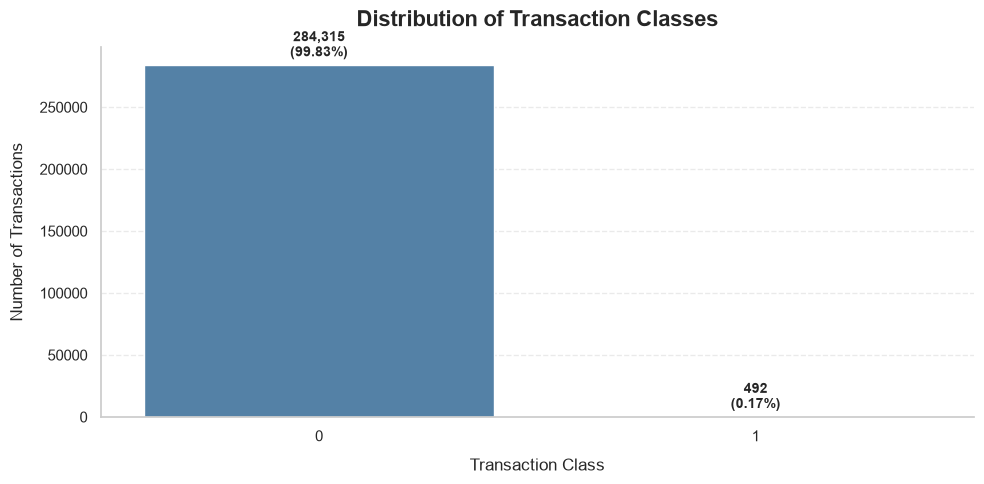

In [38]:
F_barplot(data=df, column='Class')

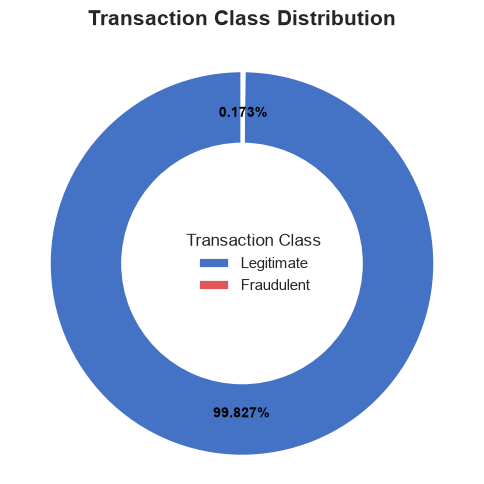

In [39]:
F_Subplot(data=df, column='Class')

#### Transaction Amount Analysis.

This analysis will be particularly important because we have previously identified that "Amount" exhibits a strong positive skew (right-skewed distribution), as well as extreme values.

Our objective is to investigate:
1. How transaction amounts are distributed.
2. Whether there are any extreme values (outliers).
3. Whether there are differences between legitimate and fraudulent transactions.

In [40]:
amount_summary = df['Amount'].describe()
amount_skewness = df['Amount'].skew()
amount_kurtosis = df['Amount'].kurt()

print(f"Transaction Amount Summary:")
print(amount_summary.round(3))
print(f"\nSkewness: {amount_skewness:.4f}")
print(f"Kurtosis: {amount_kurtosis:.4f}")

Transaction Amount Summary:
count    284807.000
mean         88.350
std         250.120
min           0.000
25%           5.600
50%          22.000
75%          77.165
max       25691.160
Name: Amount, dtype: float64

Skewness: 16.9777
Kurtosis: 845.0926


In [41]:
amount_99th_percentile = df['Amount'].quantile(0.99)

print(f"99th percentile: {round(amount_99th_percentile, 2)}")

99th percentile: 1017.97


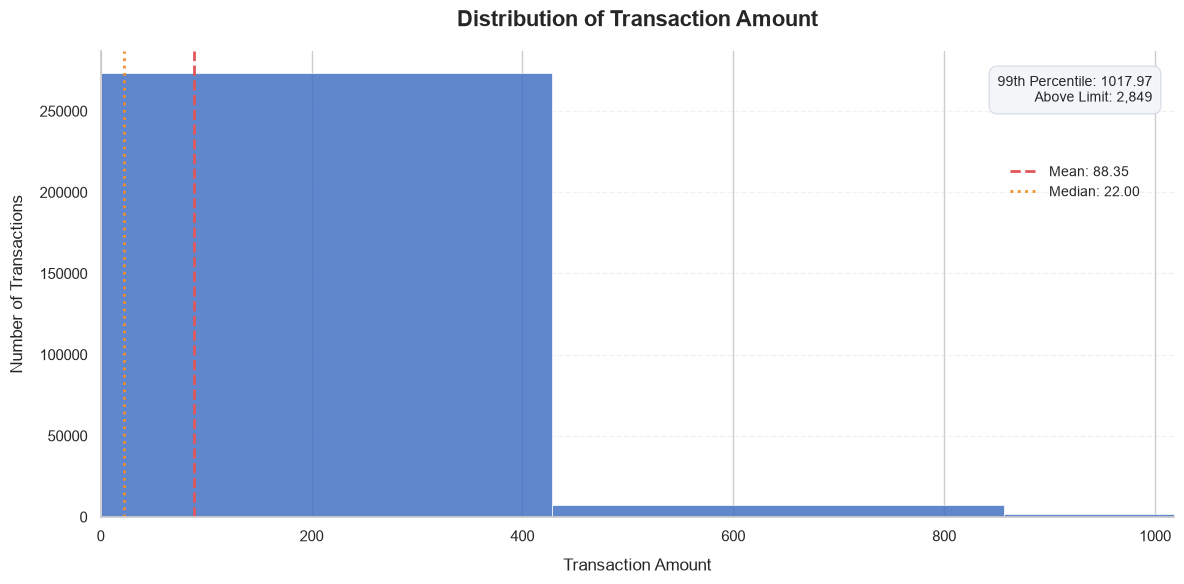

In [42]:
F_histplot(data=df, column='Amount')

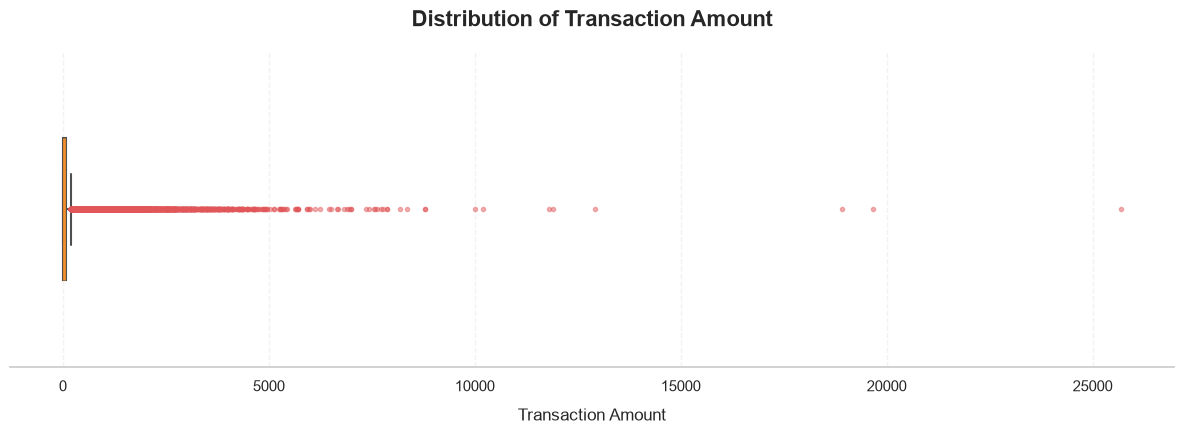

In [43]:
F_boxplot(data=df, column='Amount')

In [44]:
Q1 = df['Amount'].quantile(0.25)
Q3 = df['Amount'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

outliers = df[
    (df['Amount'] < lower_bound) |
    (df['Amount'] > upper_bound)
]

print(f"Q1: {Q1:.4f}")
print(f"Q3: {Q3:.4f}")
print(f"IQR: {IQR:.4f}")

print(f"\nLower bound: {lower_bound:.4f}")
print(f"Upper bound: {upper_bound:.4f}")

print(f"\nPotential outliers: {len(outliers):,}")

print(
    f"Outlier percentage: "
    f"{len(outliers) / len(df) * 100:.4f}%"
)

Q1: 5.6000
Q3: 77.1650
IQR: 71.5650

Lower bound: -101.7475
Upper bound: 184.5125

Potential outliers: 31,904
Outlier percentage: 11.2020%


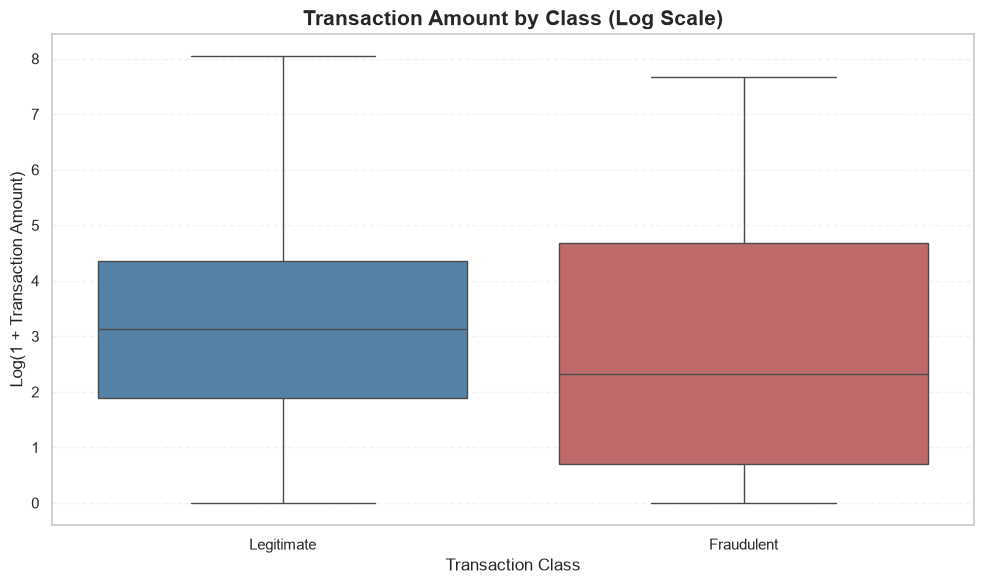

In [45]:
F_barplot_v1(data=df, column=['Amount', 'Class'])

In [46]:
amount_class_comparison = (
    df.groupby('Class')['Amount']
    .agg([
        'count',
        'mean',
        'median',
        'std',
        'min',
        'max'
    ])
)

amount_class_comparison

,count,mean,median,std,min,max
Class,,,,,,
0,284315,88.291022,22.00,250.105092,0.0,25691.16
1,492,122.211321,9.25,256.683288,0.0,2125.87


#### Transaction Frequency Over Time

This analysis investigates the frequency of credit card transactions across hourly intervals. The Time variable is converted into elapsed hours and grouped into fixed one-hour intervals. 
The objective is to identify variations in transaction activity throughout the observation period and understand how transaction frequency is distributed over time.

In [47]:
time_df = df[['Time', 'Class']].copy()

time_df['Time_Hours'] = time_df['Time'] / 3600

time_df['Hour_Interval'] = (
    time_df['Time'] // 3600
).astype(int)

time_df.head()

,Time,Class,Time_Hours,Hour_Interval
0,0.0,0,0.000000,0
1,0.0,0,0.000000,0
2,1.0,0,0.000278,0
3,1.0,0,0.000278,0
4,2.0,0,0.000556,0


In [48]:
hourly_transactions = (time_df.groupby('Hour_Interval').size())
hourly_transactions = hourly_transactions.reindex(range(48),fill_value = 0)
hourly_transactions.index.name = 'Hour_Interval'

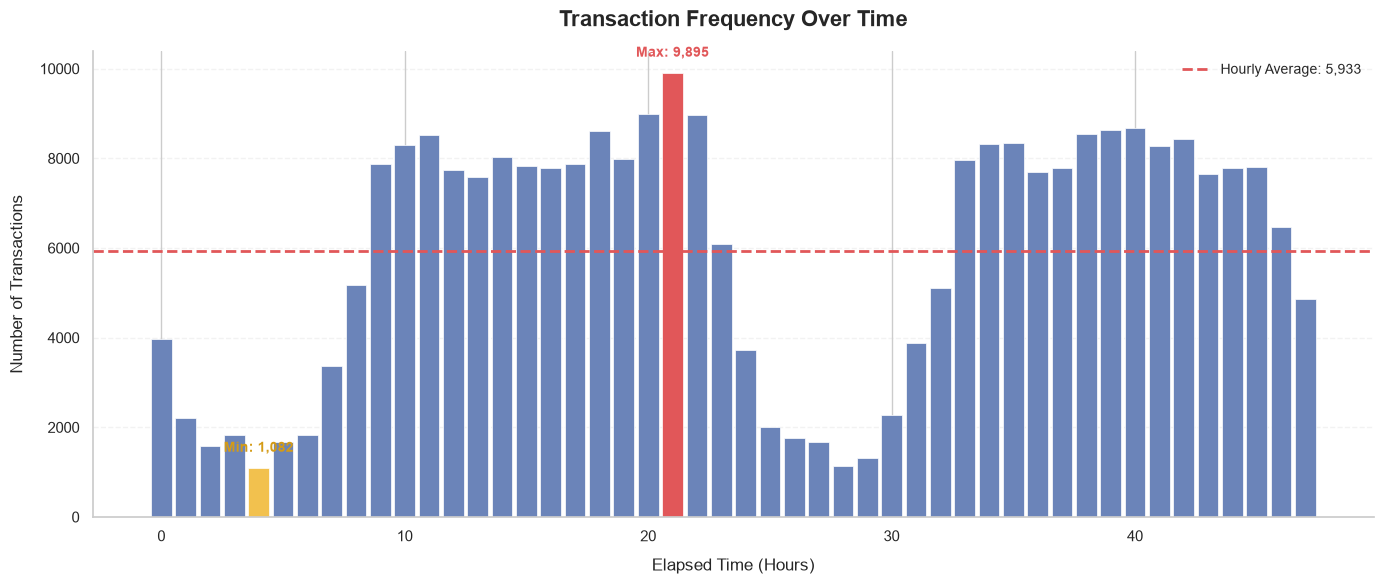

In [49]:
F_barplot_v2(data=hourly_transactions, column=None)

In [50]:
print(f"Average transactions per hour: {hourly_transactions.mean():.2f}")
print(f"Maximum transactions: {hourly_transactions.max():,}")
print(f"Peak activity interval: {hourly_transactions.idxmax()}")
print(f"Minimum transactions: {hourly_transactions.min():,}")
print(f"Lowest activity interval: {hourly_transactions.idxmin()}")

Average transactions per hour: 5933.48
Maximum transactions: 9,895
Peak activity interval: 21
Minimum transactions: 1,082
Lowest activity interval: 4


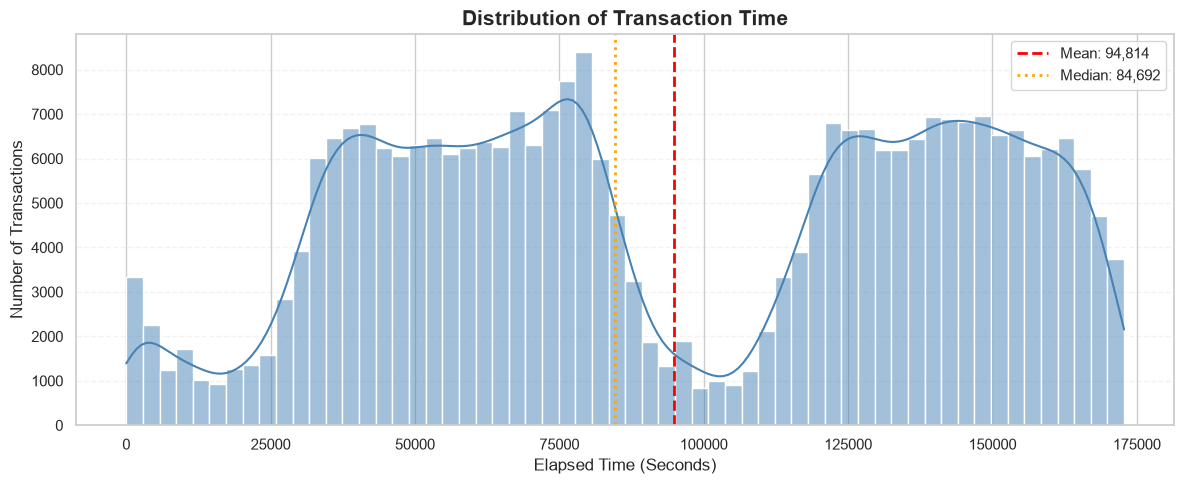

In [51]:
F_histplot_v1(data=df, column="Time")

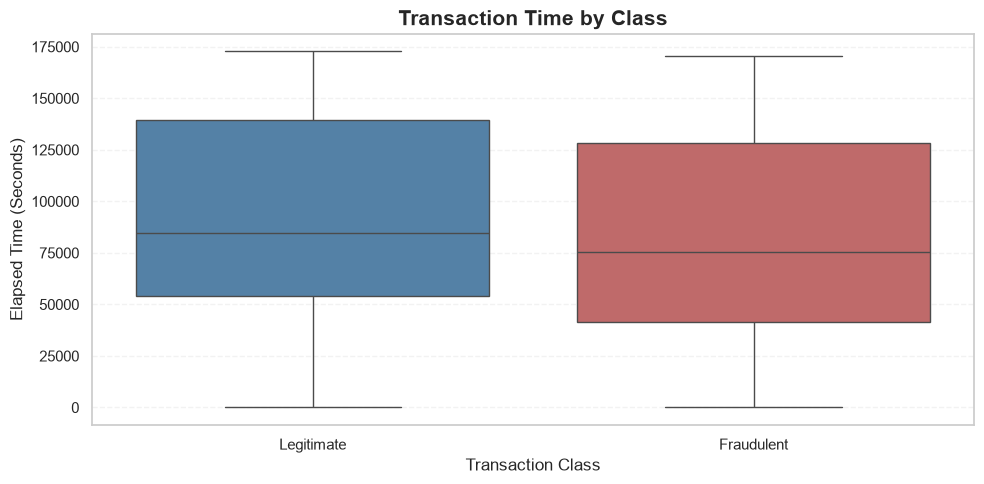

In [52]:
F_barplot_v3(data=df, column=['Time', 'Class'])

In [53]:
df.groupby('Class')['Time'].agg(
    [
        'count',
        'mean',
        'median',
        'std',
        'min',
        'max'
    ])

,count,mean,median,std,min,max
Class,,,,,,
0,284315,94838.202258,84711.0,47484.015786,0.0,172792.0
1,492,80746.806911,75568.5,47835.365138,406.0,170348.0


In [60]:
hourly_class_distribution = (
    time_df.groupby(
        ['Hour_Interval', 'Class']
    )
    .size()
    .unstack(fill_value=0)
)

hourly_class_distribution.columns = [
    'Legitimate',
    'Fraudulent'
]

hourly_class_distribution = (
    hourly_class_distribution
    .reindex(range(48), fill_value=0)
)

hourly_class_distribution['Fraud_Rate'] = (
    hourly_class_distribution['Fraudulent']
    / hourly_class_distribution[
        ['Legitimate', 'Fraudulent']
    ].sum(axis=1)
    * 100
)

2026-11-01 12:02:12,571 | INFO | File_name ~> category.py | Function ~> update | Line ~~> 224  ~~>  Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-01 12:02:12,575 | INFO | File_name ~> category.py | Function ~> update | Line ~~> 224  ~~>  Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


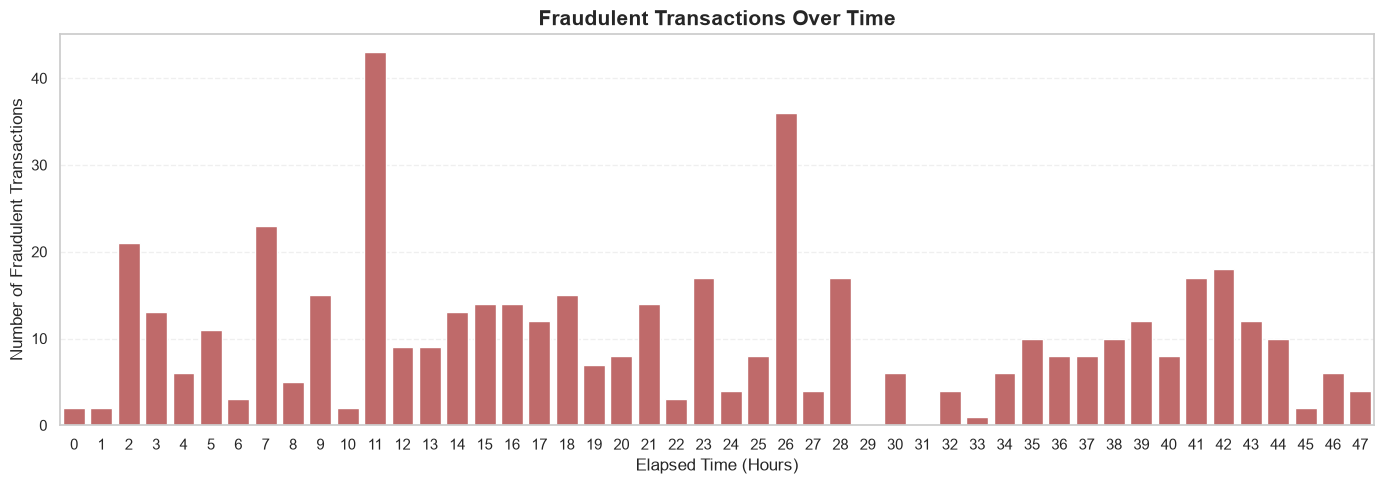

In [61]:
F_barplot_v4(data=hourly_class_distribution, column="Fraudulent")

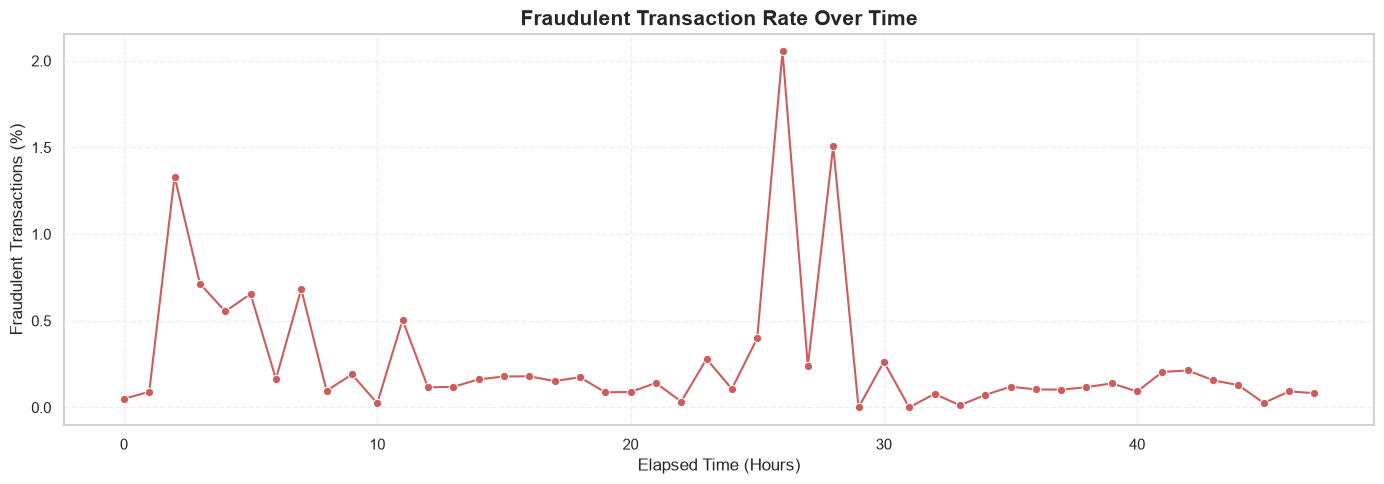

In [62]:
F_lineplot(data=hourly_class_distribution, column="Fraud_Rate")

In [58]:
hourly_summary = hourly_class_distribution[
    ['Legitimate', 'Fraudulent']
].copy()

hourly_summary['Total Transactions'] = (
    hourly_summary['Legitimate']
    + hourly_summary['Fraudulent']
)

hourly_summary['Fraud Rate (%)'] = (
    hourly_summary['Fraudulent']
    / hourly_summary['Total Transactions']
    * 100
)

hourly_summary = hourly_summary.sort_values(
    'Fraud Rate (%)',
    ascending=False
)

hourly_summary.head(10).round(4)

,Legitimate,Fraudulent,Total Transactions,Fraud Rate (%)
Hour_Interval,,,,
26,1716,36,1752,2.0548
28,1110,17,1127,1.5084
2,1555,21,1576,1.3325
3,1808,13,1821,0.7139
7,3345,23,3368,0.6829
5,1670,11,1681,0.6544
4,1076,6,1082,0.5545
11,8474,43,8517,0.5049
25,1995,8,2003,0.3994


#### 6.5 Feature Distribution Analysis

- This section investigates the statistical characteristics and distributions of the anonymized PCA components (V1–V28).
- Histograms and comparative boxplots will be used to examine feature distributions, variability, and potential differences between legitimate and fraudulent transactions.
- The analysis aims to identify components that exhibit distinct statistical patterns across transaction classes and provide insights into their potential relevance for subsequent classification analysis.
- Since these variables were generated through Principal Component Analysis (PCA), their original meanings are not directly interpretable.

In [67]:
pca_features = [
    f'V{i}' for i in range(1, 29)
]

pca_df = df[pca_features + ['Class']].copy()

pca_df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0


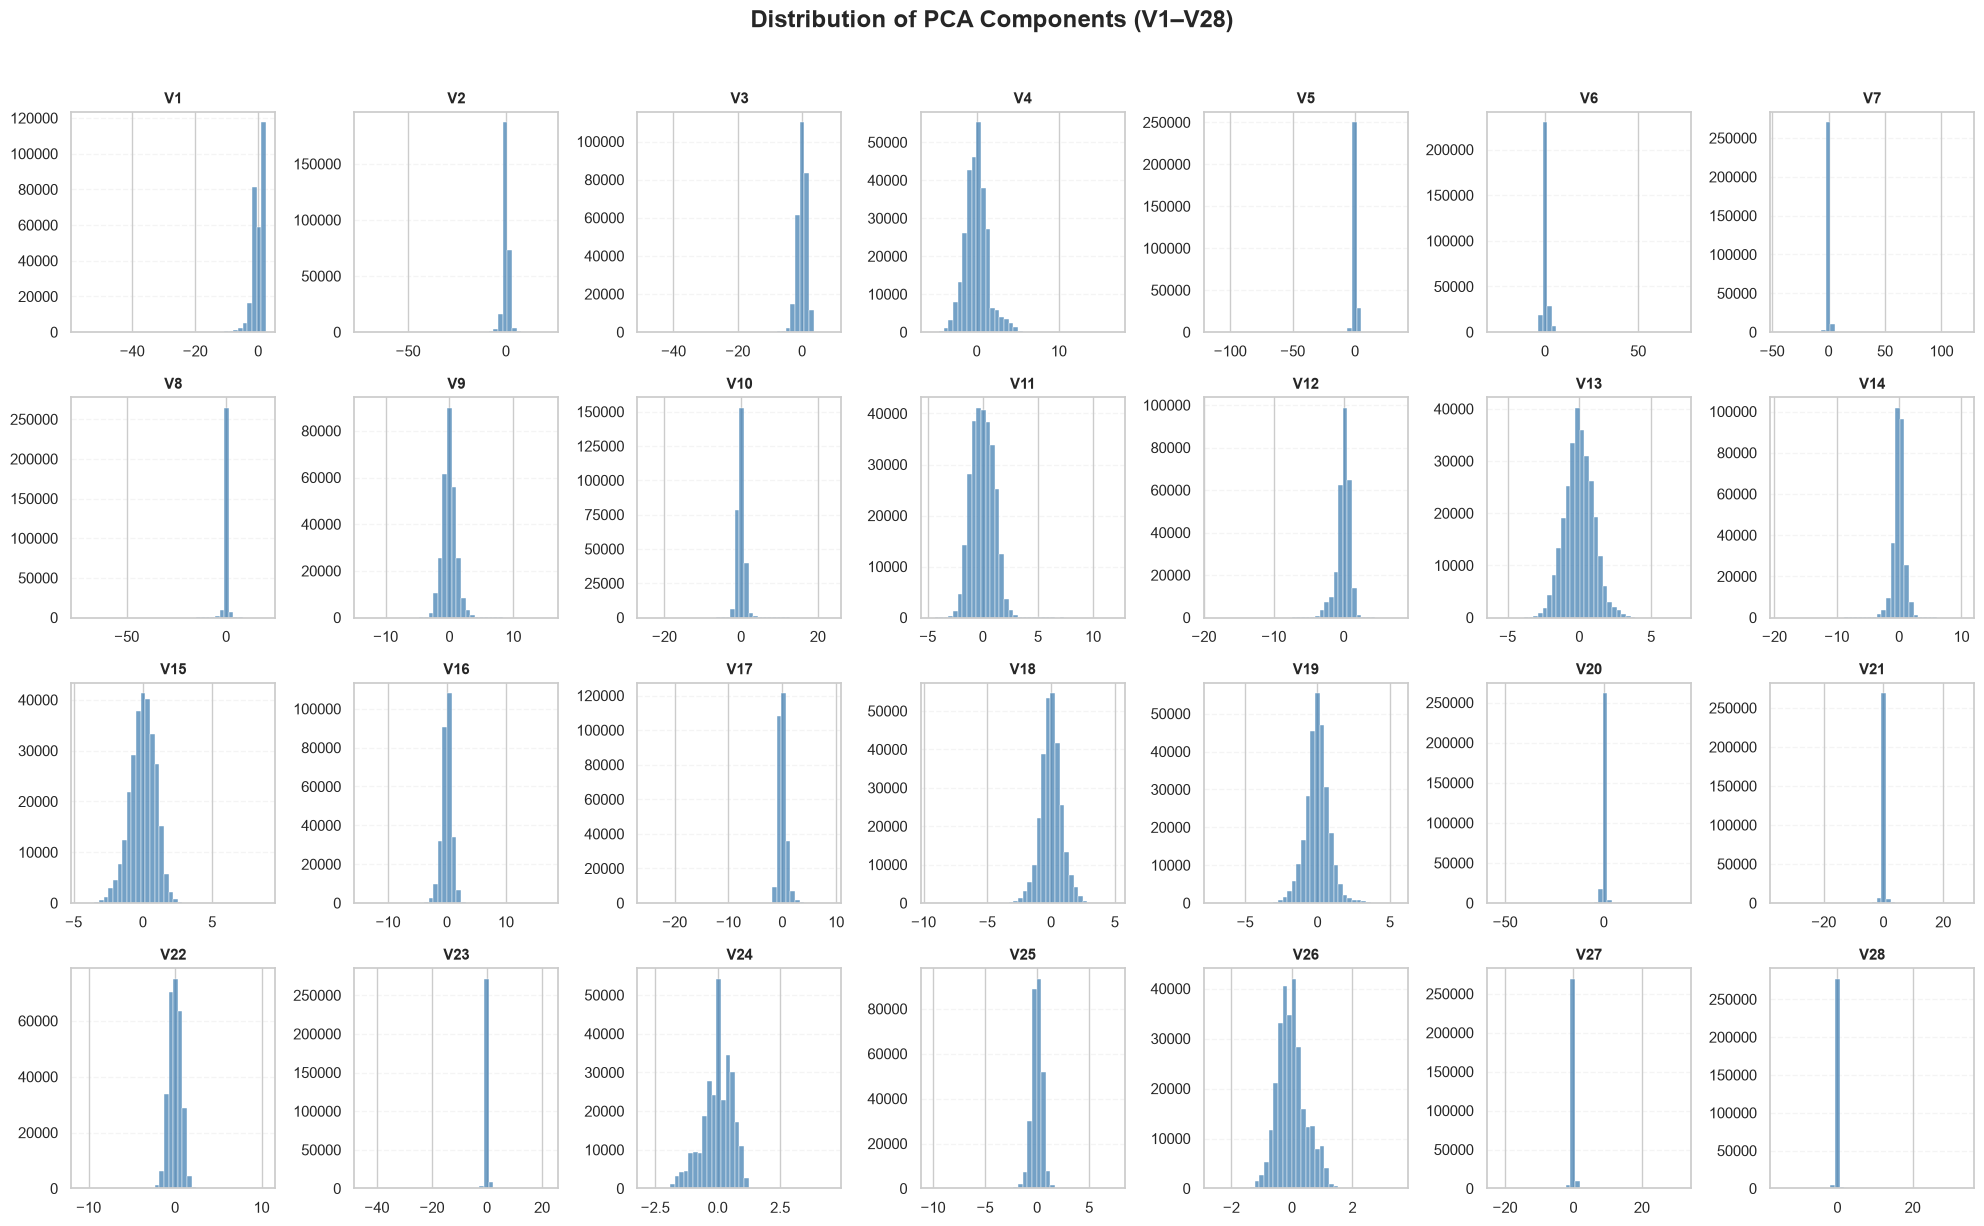

In [65]:
F_histplot_v2(pca_data=pca_df, pca_list=pca_features)

In [68]:
pca_statistics = pd.DataFrame({
    'Mean': pca_df[pca_features].mean(),
    'Std': pca_df[pca_features].std(),
    'Variance': pca_df[pca_features].var(),
    'Skewness': pca_df[pca_features].skew(),
    'Kurtosis': pca_df[pca_features].kurt()
})

pca_statistics

,Mean,Std,Variance,Skewness,Kurtosis
V1,1.175161e-15,1.958696,3.836489,-3.280667,32.486679
V2,3.384974e-16,1.651309,2.726820,-4.624866,95.773106
V3,-1.379537e-15,1.516255,2.299029,-2.240155,26.619551
V4,2.094852e-15,1.415869,2.004684,0.676292,2.635455
V5,1.021879e-15,1.380247,1.905081,-2.425901,206.904560
V6,1.494498e-15,1.332271,1.774946,1.826581,42.642494
V7,-5.620335e-16,1.237094,1.530401,2.553907,405.607417
V8,1.149614e-16,1.194353,1.426479,-8.521944,220.586974
V9,-2.414189e-15,1.098632,1.206992,0.554680,3.731311
V10,2.238554e-15,1.088850,1.185594,1.187141,31.988239


Feature variability

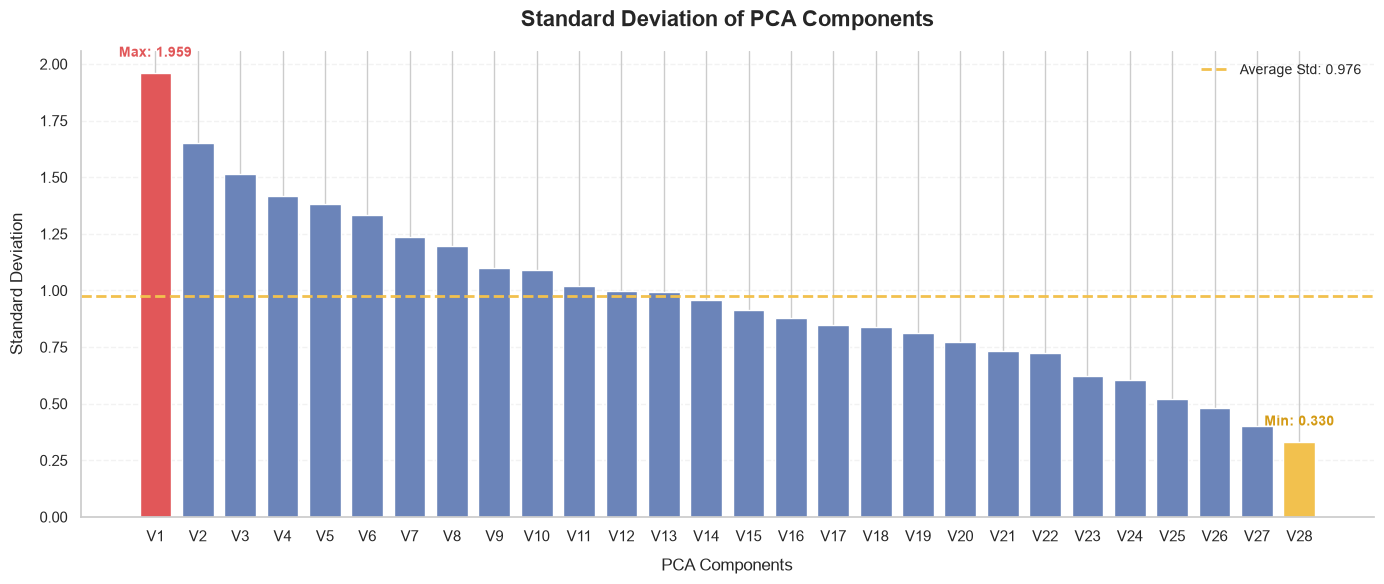

In [82]:
F_barplot_v5(pca_data=pca_df, pca_list=pca_features)

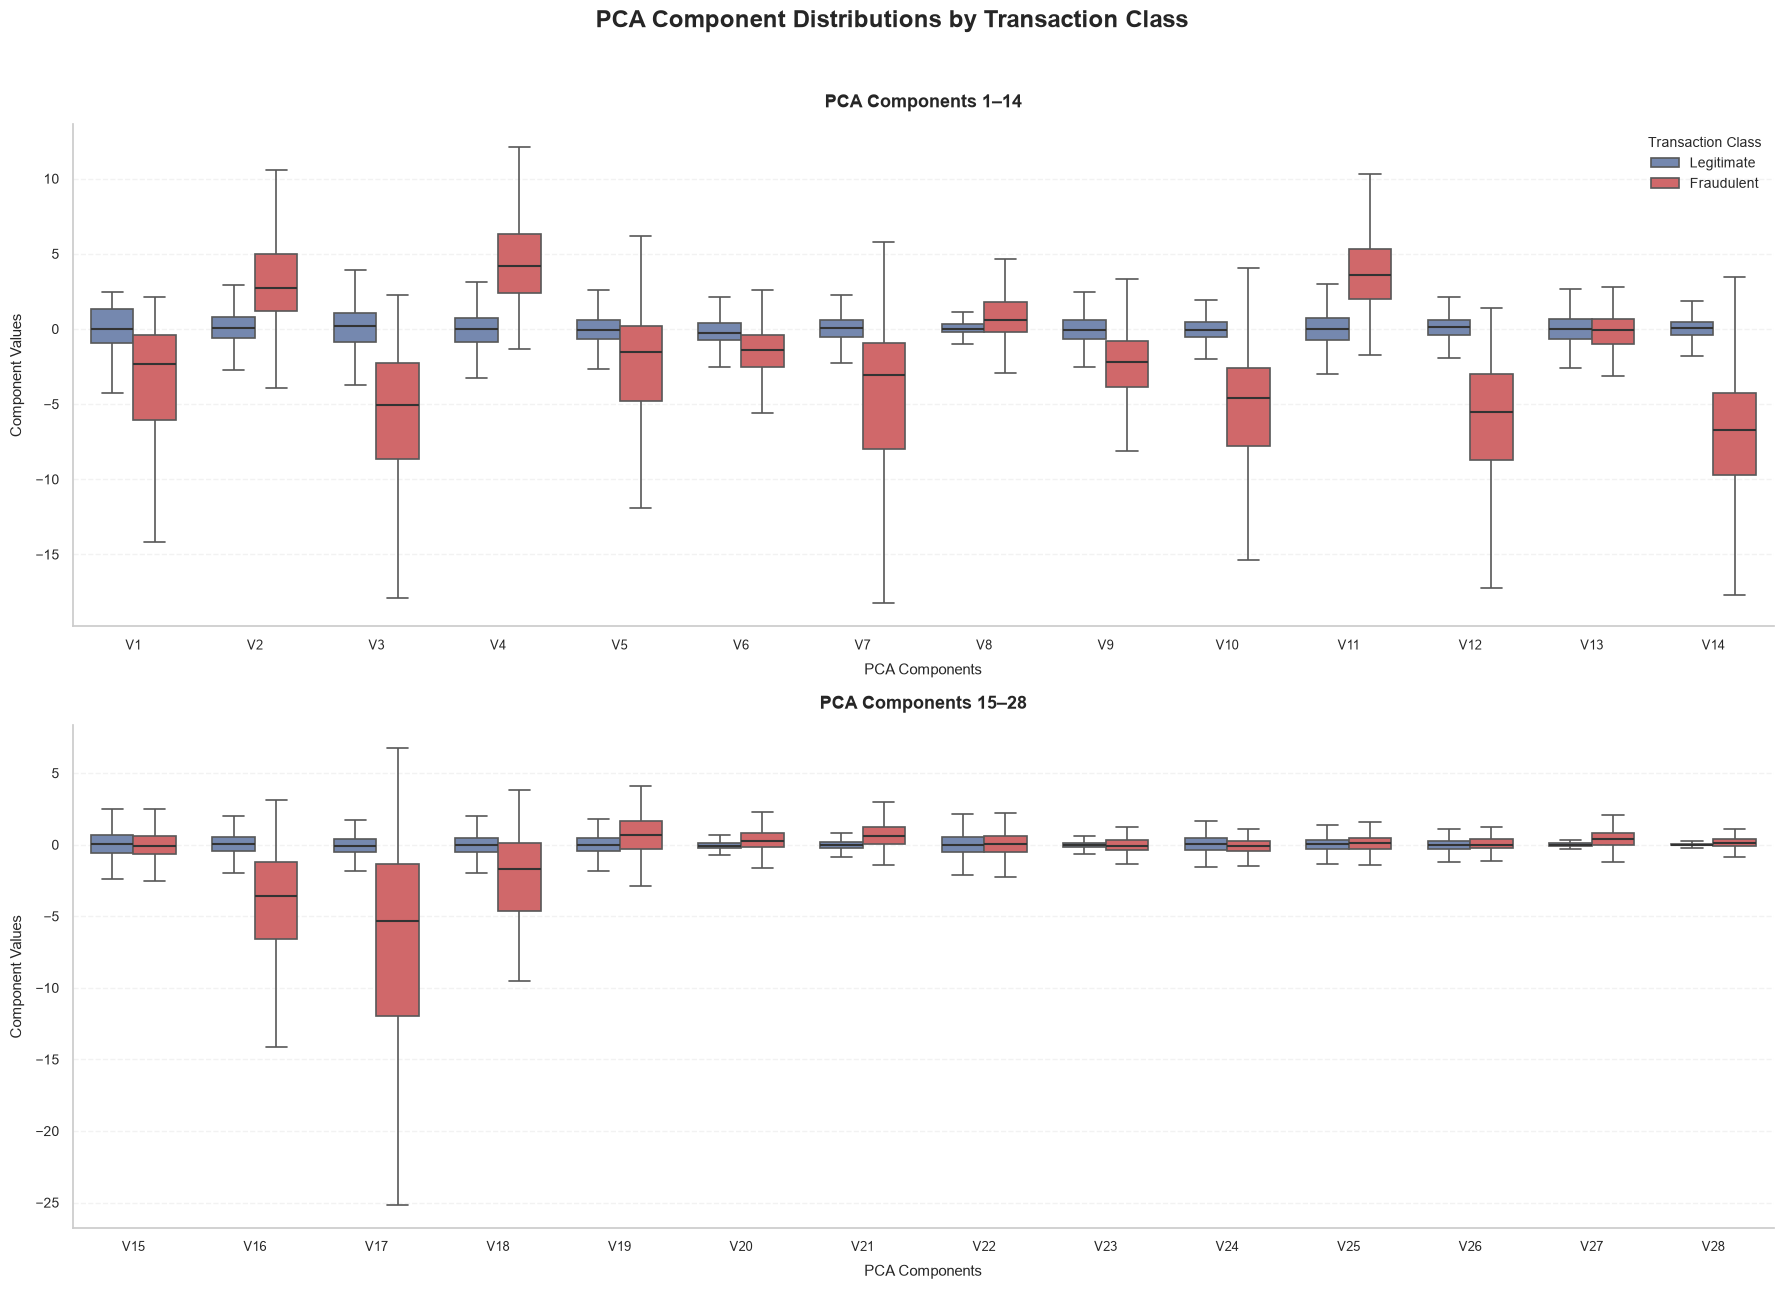

In [87]:
F_boxplot(pca_data=pca_df, pca_list=pca_features)

In [91]:
pca_class_comparison = (
    pca_df.groupby('Class')[pca_features]
    .agg(['median', 'std'])
)

pca_class_comparison

V1                  V2                  V3                  V4  \
         median       std    median       std    median       std    median   
Class                                                                         
0      0.020023  1.929814  0.064070  1.636146  0.182158  1.459429 -0.022405   
1     -2.342497  6.783687  2.717869  4.291216 -5.075257  7.110937  4.177147   

                       V5            ...       V24                 V25  \
            std    median       std  ...    median       std    median   
Class                                ...                                 
0      1.399333 -0.053457  1.356952  ...  0.041082  0.605776  0.016417   
1      2.873318 -1.522962  5.372468  ... -0.060795  0.515577  0.088371   

                      V26                 V27                 V28            
            std    median       std    median       std    median       std  
Class                                                                        
0      0.520673 -0.052227  0.482241  0.001230  0.399847  0.011199  0.329570  
1      0.797205  0.004321  0.471679  0.394926  1.376766  0.146344  0.547291  

[2 rows x 56 columns]

In [93]:
legitimate_median = (pca_df[pca_df['Class'] == 0][pca_features].median())
fraudulent_median = (pca_df[pca_df['Class'] == 1][pca_features].median())
median_comparison = pd.DataFrame({
    'Legitimate Median': legitimate_median,
    'Fraudulent Median': fraudulent_median})

median_comparison['Absolute Difference'] = (median_comparison['Fraudulent Median'] - median_comparison['Legitimate Median']).abs()
median_comparison = median_comparison.sort_values('Absolute Difference', ascending=False)

median_comparison

,Legitimate Median,Fraudulent Median,Absolute Difference
V14,0.051947,-6.729720,6.781667
V12,0.141679,-5.502530,5.644208
V3,0.182158,-5.075257,5.257415
V17,-0.064833,-5.302949,5.238115
V10,-0.091872,-4.578825,4.486953
V4,-0.022405,4.177147,4.199552
V11,-0.034923,3.586218,3.621142
V16,0.067377,-3.549795,3.617172
V7,0.041138,-3.034402,3.075540
V2,0.064070,2.717869,2.653799


In [105]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

statistical_results = []

for feature in pca_features:

    legitimate = pca_df.loc[pca_df['Class'] == 0, feature]
    fraudulent = pca_df.loc[pca_df['Class'] == 1, feature]

    statistic, p_value = mannwhitneyu(fraudulent, legitimate, alternative='two-sided')

    effect_size = (
        (2 * statistic) /
        (len(fraudulent) * len(legitimate))
    ) - 1

    statistical_results.append(
        {
            'Feature': feature,
            'U Statistic': statistic,
            'P Value': p_value,
            'Effect Size': effect_size
        })

statistical_results = pd.DataFrame(statistical_results)

statistical_results['Adjusted P Value'] = (
    multipletests(
        statistical_results['P Value'],
        method='fdr_bh'
    )[1]
)

statistical_results = (statistical_results.sort_values('Adjusted P Value').reset_index(drop=True))
statistical_results

,Feature,U Statistic,P Value,Effect Size,Adjusted P Value
0,V14,7111691.0,1.471581e-260,-0.898319,4.120426e-259
1,V4,131246382.0,3.625904e-248,0.876517,5.076266e-247
2,V12,8806982.0,8.416027e-247,-0.874081,7.854958e-246
3,V11,128424209.0,4.910592e-226,0.836166,3.437414e-225
4,V10,12021914.0,9.611131e-222,-0.828115,5.382233e-221
5,V3,12299525.0,1.211048e-219,-0.824146,5.651558e-219
6,V2,119593684.0,1.650438e-163,0.709910,6.601751e-163
7,V16,21383707.0,1.808172e-156,-0.694263,6.328603e-156
8,V9,21809136.0,8.943723e-154,-0.688180,2.782492e-153
9,V7,22967158.0,1.464234e-146,-0.671623,4.099854e-146


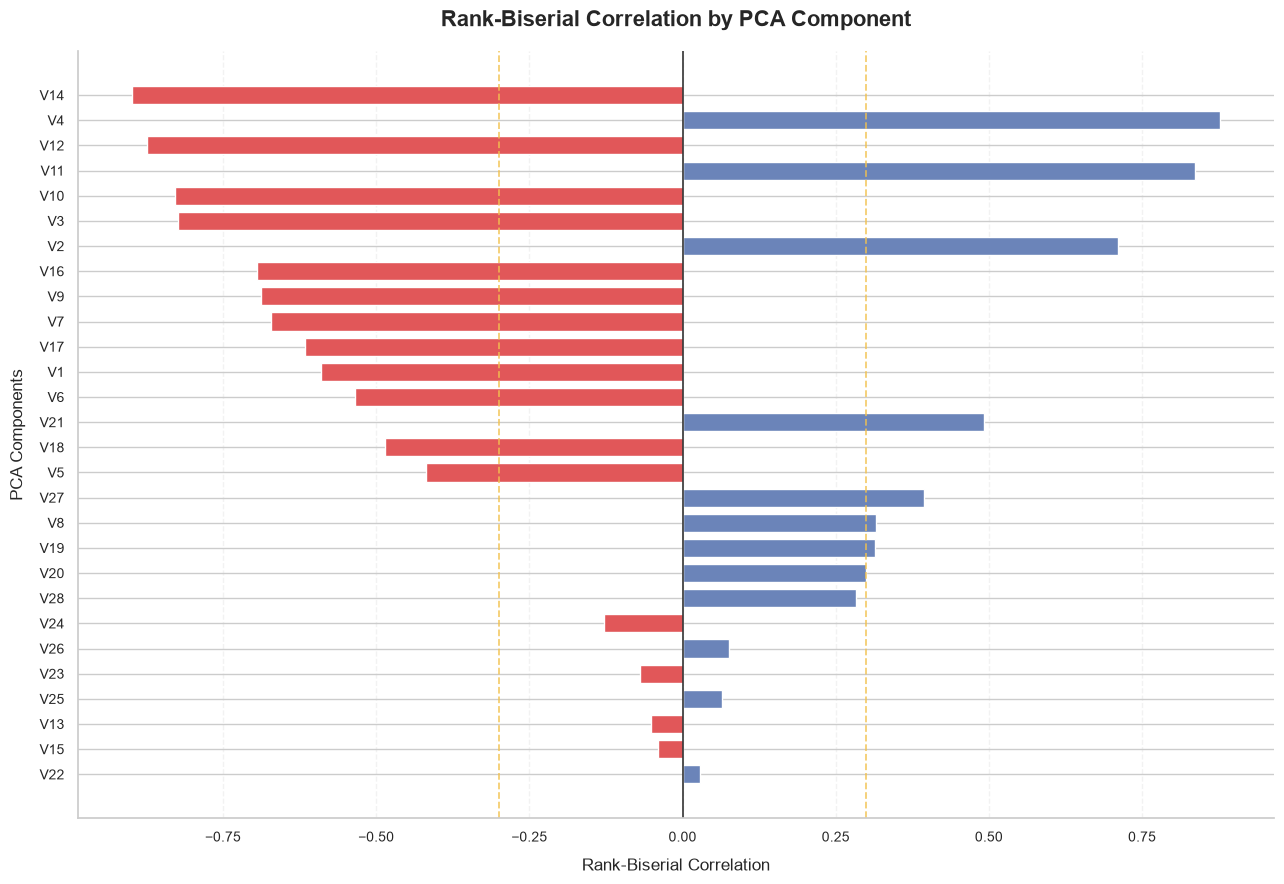

In [104]:
F_barh(statistical_data = statistical_results)

##### Result --> Statistical Significance and Effect Size Analysis

The Mann–Whitney U test was applied to investigate differences in the distributions of the 28 PCA components between legitimate and fraudulent transactions.

To account for multiple hypothesis testing, the Benjamini-Hochberg procedure was applied using a false discovery rate of 5%.

The results indicated statistically significant differences in 25 out of the 28 components. V13, V15, and V22 did not reach statistical significance after multiple-testing correction.

The effect size analysis, based on rank-biserial correlation, revealed particularly strong distributional separation for V14 (-0.8983), V4 (0.8765), V12 (-0.8741), V11 (0.8362), and V10 (-0.8281).

The direction of the effect indicates whether fraudulent transactions tend to exhibit higher or lower values compared with legitimate transactions.

These findings are consistent with the descriptive analysis and comparative boxplots, providing additional statistical evidence of differences between the transaction classes.

However, statistical significance and effect size should not be interpreted as direct measures of predictive performance. The actual contribution of these components to fraud detection must be evaluated through classification models and appropriate validation procedures.

### 👨🏾‍🔬 Probability Distributions

#### 🔬 Binomial Distribution

The Binomial distribution will be investigated using the binary Class variable.

Each transaction represents a trial with two possible outcomes:

- Success: Fraudulent transaction (Class = 1).
- Failure: Legitimate transaction (Class = 0).

The probability of fraud will be estimated from the observed proportion of fraudulent transactions.

The analysis will investigate:

- The probability of fraudulent transactions.
- Expected number of fraudulent transactions
  in a fixed sample.
- Variance and standard deviation.
- Probability of observing a specific number
  of fraudulent transactions.
- The behaviour of the distribution as sample
  size increases.

The theoretical results will be compared with observed data.

#### 🔬 Poisson Distribution

The Poisson distribution will be investigated to model the number of transactions occurring within fixed time intervals. The Time variable will be used to organise transactions into defined intervals.

The analysis will investigate:

- Transaction counts per time interval.
- Average event rate (lambda).
- Probability of observing a specific number
  of transactions.
- Comparison between observed and theoretical
  frequencies.
- The behaviour of the distribution with
  larger samples.

The assumptions of the Poisson distribution, including independence and a reasonably stable event rate, will be critically evaluated. The suitability of the model will be discussed based on the observed data.

#### 🔬 Normal Distribution

This section investigates the suitability of the Normal distribution for selected continuous numerical variables.

The analysis will focus on:

- Mean and standard deviation.
- Distribution shape.
- Skewness and kurtosis.
- Histogram and density visualization.
- Comparison between empirical and theoretical
  Normal distributions.
- Probability calculations using the Normal model.

The selected variables will be evaluated to determine whether the Normal distribution provides a reasonable approximation. Any deviations from Normality will be discussed and interpreted.

### ⚖ Statistical Comparison

This section compares the discrete and continuous probability distributions applied throughout the analysis.

The discussion will cover:

- Differences between discrete and continuous
  probability distributions.
- Suitability of the Binomial distribution
  for binary transaction outcomes.
- Suitability of the Poisson distribution
  for transaction counts.
- Suitability of the Normal distribution
  for continuous numerical variables.
- Impact of skewness and class imbalance.
- Limitations and assumptions of each model.

🎯 The objective is to justify the selection of each distribution and explain its relevance to the dataset.

### 📊 Conclusion